In [3]:
#from sklearn.datasets import load_boston
#boston_dataset = load_boston()
import pandas as pd
df = pd.read_csv('boston_house_prices.csv')

In [4]:
#description = boston_dataset.DESCR
#print(description)
df.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [5]:
#import pandas as pd

In [6]:
#df = pd.DataFrame(boston_dataset.data,columns=boston_dataset.feature_names)
#df.head()

In [7]:
#df['MEDV'] = boston_dataset.target[df.index]


In [8]:
print(df.index)
print(df.shape)

RangeIndex(start=0, stop=506, step=1)
(506, 14)


In [9]:
df_ = df
df = df.sample(20, random_state=150)

In [10]:
df = df.sample(20, random_state=150)
df

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
230,0.53700,0.0,6.20,0,0.504,5.981,68.1,3.6715,8,307,17.4,378.35,11.65,24.3
60,0.14932,25.0,5.13,0,0.453,5.741,66.2,7.2254,8,284,19.7,395.11,13.15,18.7
74,0.07896,0.0,12.83,0,0.437,6.273,6.0,4.2515,5,398,18.7,394.92,6.78,24.1
170,1.20742,0.0,19.58,0,0.605,5.875,94.6,2.4259,5,403,14.7,292.29,14.43,17.4
353,0.01709,90.0,2.02,0,0.410,6.728,36.1,12.1265,5,187,17.0,384.46,4.50,30.1
78,0.05646,0.0,12.83,0,0.437,6.232,53.7,5.0141,5,398,18.7,386.40,12.34,21.2
114,0.14231,0.0,10.01,0,0.547,6.254,84.2,2.2565,6,432,17.8,388.74,10.45,18.5
130,0.34006,0.0,21.89,0,0.624,6.458,98.9,2.1185,4,437,21.2,395.04,12.60,19.2
119,0.14476,0.0,10.01,0,0.547,5.731,65.2,2.7592,6,432,17.8,391.50,13.61,19.3
116,0.13158,0.0,10.01,0,0.547,6.176,72.5,2.7301,6,432,17.8,393.30,12.04,21.2


In [11]:
from sklearn.linear_model import LinearRegression
X = df["RM"].values.reshape(-1,1)
y = df["MEDV"].values.reshape(-1, 1)

$$\widehat{y} = f( X )$$
Donde:
- f: es nuestro modelo
- X: es las variables de entrada
- $\widehat{y}$ : es la estimación

In [12]:
reg = LinearRegression().fit(X,y)
y_hat = reg.predict(X)

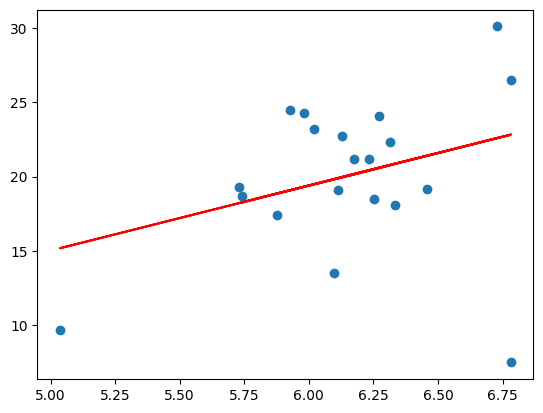

In [13]:
import matplotlib.pyplot as plt
plt.scatter(X, y)
plt.plot(X, y_hat,"r-")

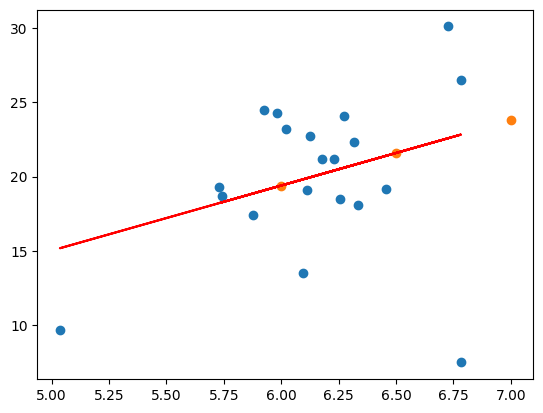

In [14]:
plt.scatter(X, y)
plt.plot(X, y_hat,"r-")
test_points_X = [[6.00],[6.50],[7.00]]
test_points_y = reg.predict(test_points_X)
plt.scatter(test_points_X,test_points_y)

#Os puntos preditos dame sobre a recta de regresion, como era de esperar.

In [15]:
from sklearn.metrics import r2_score
r2_score(y,y_hat)

0.10802970905334186

### ¿Es posible mejorarla aún?

In [16]:
X = df["LSTAT"].values.reshape(-1,1)
y = df["MEDV"].values.reshape(-1, 1)
reg = LinearRegression().fit(X,y)

In [17]:
y_hat = reg.predict(X)

array([[24.77488205],
       [22.09693479]])

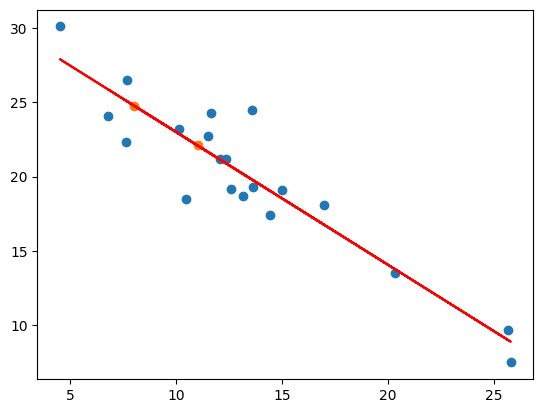

In [18]:
plt.scatter(X,y)
plt.plot(X,reg.predict(X),"r-")
test_points_X = [[8],[11]]
test_points_y = reg.predict(test_points_X)
plt.scatter(test_points_X,test_points_y)
test_points_y

In [19]:
r2_score(y,y_hat)

0.8576479263502265

### ¿Se puede mejorar aún mas?

In [ ]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
import matplotlib.pyplot as plt

# Imos facer un axuste polinómico en lugar de lineal

from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

X = df["LSTAT"].values.reshape(-1, 1)
y = df["MEDV"].values.reshape(-1, 1)
train_test = False

def plot(degree = 1, show=True):
    global y_hat
    global poly
    global reg
    global x_model
    global X,y
#   global y
#   plt.figure(figsize=(5,5))
    poly = PolynomialFeatures(degree=degree)
    if train_test:
        X = X_train
        y = y_train
    X_ = poly.fit_transform(X)
    reg = LinearRegression().fit(X_,y)
    y_hat = reg.predict(X_)
    plt.scatter(X,y)
    x_model = np.linspace(0,20,num=100)
    y_model = reg.predict(poly.transform(x_model.reshape(-1,1)))
    line, = plt.plot(x_model, y_model,"--r")
    plt.axis([0, 20, 0, 40])
    plt.xlabel("LSTAT")
    plt.ylabel("MEDV")
    r2 = r2_score(y,y_hat)
    r2 = "{:.3f}".format(r2)
    plt.text(1, 1, r'$R^2 = '+str(r2)+'$', fontsize=15)
    if show:
        print("R2:",r2)
        test_data = [[5], [7.5],[14]]
        predictions = reg.predict(poly.transform(test_data))
        for _x_,_y_ in zip(test_data,predictions):
            print("Con un LSTAT de",_x_[0],"se predice un precio de","{:.3f}".format(_y_[0]))
        plt.show()

interact(plot,degree=(1,10));

interactive(children=(IntSlider(value=1, description='degree', max=10, min=1), Checkbox(value=True, descriptio…

## ¿Cuál escoger?

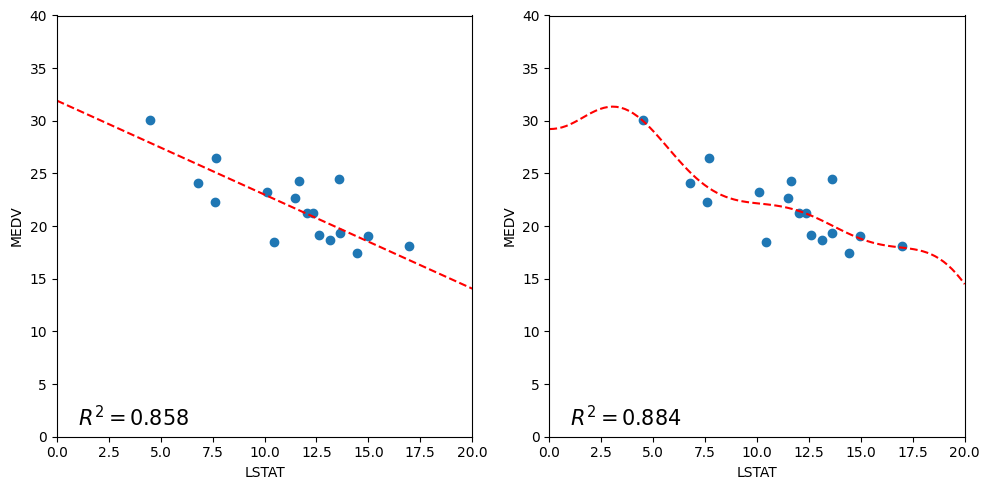

In [25]:
plt.figure(figsize=(10,5))
plt.subplot(1, 2, 1)
plot(1,show=False)
plt.subplot(1, 2, 2)
plot(10,show=False)
plt.tight_layout()

<p style='text-align: justify;'>El modelo de la izquierda se intenta ajustar una linea para que pase por todos los puntos de nuestro dataset. Los datos que tenemos son intrinsicamente mas complicados que una linea por lo tanto encontrar una linea que decribe nuestros datos es una tarea imposible. El modelo  nunca podra adaptarse a la perfección a nuestros datos por su falta de de flexibilidad para adaptarse. Se dice que el modelo tiene un bajo ajuste <font color = green>__(underfit)__</font>  a los datos. Otra forma de decir esto es que el modelo tiene un alto sesgo <font color = green>__(bias)__</font>. </p>

<p style='text-align: justify;'>El modelo de la derecha intenta ajustar un polinomio a través de los datos.
Aquí, el ajuste del modelo tiene suficiente flexibilidad para dar cuenta casi perfectamente con todos los datos. A pesar de ello, parece que el modelo aprende las perturbaciones aleatorias de los datos. Se dice que este modelo sobreajusta <font color = green>__(overfit)__</font> el modelo por que aprendio tando de los datos como los errores aleatorios que contienen. Otra forma de decir esto es que el modelo tiene una alta varianza <font color = green>__(variance)__</font>.</p>

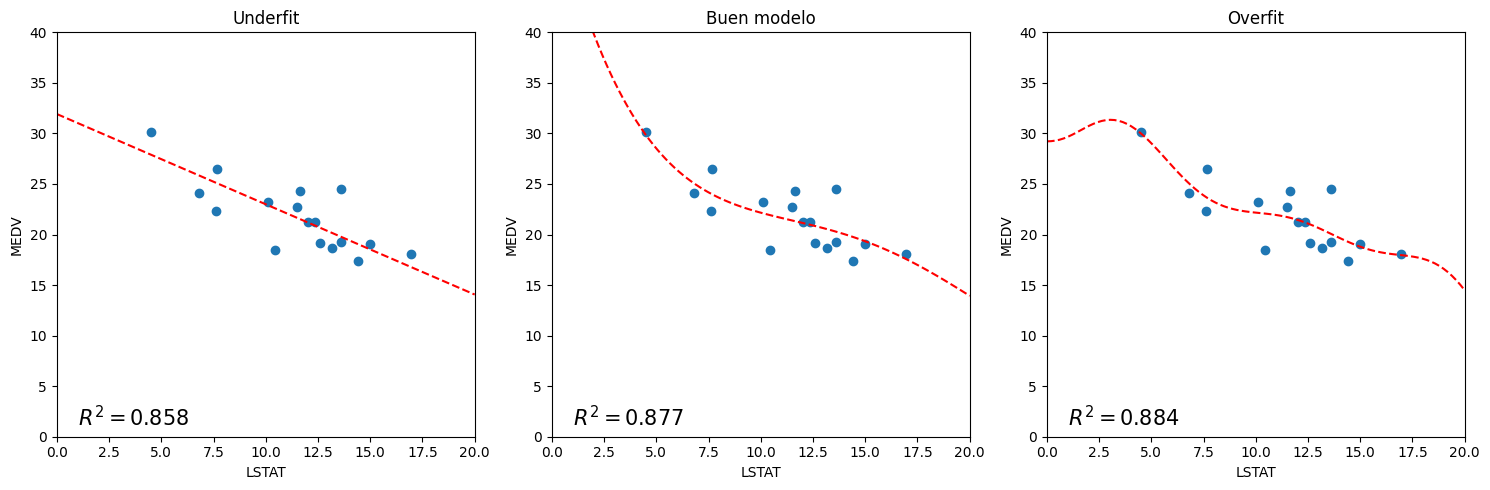

In [26]:
plt.figure(figsize=(15,5))
plt.subplot(1, 3, 1)
plot(1,show=False)
plt.title("Underfit")
plt.subplot(1, 3, 2)
plot(4,show=False)
plt.title("Buen modelo")
plt.subplot(1, 3, 3)
plot(10,show=False)
plt.title("Overfit")
plt.tight_layout()

<p style='text-align: justify;'>Un buen modelo es aquel que puede hacer buenas predicciones con datos que no haya visto con anterioridad. ¿Cómo podemos probar si el modelo puede predecir correctamente estos datos? </p>

## Utilizando splits

In [27]:
df=df_.sample(20, random_state=100) #recuperando el dataset original
from sklearn.model_selection import train_test_split
X = df["LSTAT"].values.reshape(-1,1)
y = df["MEDV"].values.reshape(-1, 1)

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=100)

In [29]:
print("df:", df.shape)
print("X:", X.shape)
print("X train:", X_train.shape)
print("X test:", X_test.shape)

df: (20, 14)
X: (20, 1)
X train: (13, 1)
X test: (7, 1)


In [30]:
def plot(degree = 1):
    poly = PolynomialFeatures(degree=degree)
    poly.fit_transform(X_train)

    reg = LinearRegression().fit(poly.transform(X_train),y_train)

    plt.scatter(X_train,y_train)
    plt.scatter(X_test,y_test)

    y_train_hat = reg.predict(poly.transform(X_train))
    y_test_hat = reg.predict(poly.transform(X_test))

    x_model = np.linspace(0,20).reshape((-1,1))
    y_model = reg.predict(poly.transform(x_model))
    plt.plot(x_model,y_model, "r--")
    plt.axis([0, 20, 0, 40])

    print("R2 train:",r2_score(y_train,y_train_hat))
    print("R2 test:",r2_score(y_test,y_test_hat))
    
    plt.show()

interact(plot,degree=(1,10));

interactive(children=(IntSlider(value=1, description='degree', max=10, min=1), Output()), _dom_classes=('widge…